# exrqa example: the Mackey–Glass delay system

This notebook applies the **`exrqa`** tool (LM2P recurrence plot and DDET, Wendi & Marwan 2018, Chaos **28**, 085722) to the **Mackey–Glass equation** (Mackey & Glass 1977), a model of blood-cell production with a delayed feedback:

$$\dot x(t) = \beta\,\frac{x(t-\tau_d)}{1 + x(t-\tau_d)^{n}} - \gamma\,x(t),$$

with $\beta = 0.2$, $\gamma = 0.1$, $n = 10$ and the delay $\tau_d$ as control parameter. To avoid a clash with the embedding delay τ, the Mackey–Glass delay is written $\tau_d$. A delay equation has an infinite-dimensional state (the whole history over one delay), but its attractor is low-dimensional. The orbit is a limit cycle for small $\tau_d$, period-doubles from $\tau_d \approx 13$ and becomes chaotic near $\tau_d \approx 16.8$. The attractor dimension then keeps growing with the delay (about 2.1 at $\tau_d = 17$, the classic benchmark, and 3.6 at $\tau_d = 30$; Farmer 1982).

Observable: $x(t)$, sampled at dt = 1, the usual sampling of this benchmark.

The method itself is explained step by step in `lorenz_example.ipynb`. This notebook applies it directly.

**Contents:** 1 test signal · 2 choosing τm · 3 RPs under noise · 4 parameter sweep · 5 noise level · 6 sampling rate and embedding · 7 distance from random noise · 8 takeaways

Runtime is about 2–3 minutes, mostly the parameter sweep in section 4 and the noise-level AUC in section 7.

In [1]:
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

try:
    import exrqa as xr
except ImportError:                       # use the local package without installing it
    sys.path.insert(0, str(pathlib.Path.cwd().parent))
    import exrqa as xr

# chart style: thin marks, recessive axes and grid
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.6, "grid.linestyle": "-",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10, "axes.titlesize": 10.5, "lines.linewidth": 1.8, "lines.markersize": 5,
    "legend.frameon": False, "legend.fontsize": 9,
})
# one fixed colour per entity, the same as in lorenz_example.ipynb
C = {"clean": "#2a78d6", "LMT": "#eb6834", "LM2P": "#1baf7a", "noise": "#8f8e89", "ink": "#52514e"}

### System settings

Everything specific to this system is in the next cell. Change it to explore other parameter ranges.

In [2]:
SYS, PNAME = "Mackey–Glass", "τ_d"
dt = 1.0                       # the usual benchmark sampling
m, tau = 5, 6                  # a higher-dimensional attractor needs m = 5 (see section 6)
N = 1000                       # RP size
P_CHAOS, P_PER = 17.0, 14.0    # classic chaotic benchmark; a period-doubled orbit
grid = np.round(np.arange(8, 30.01, 0.25), 3)

def simulate(tau_d, n, fine=1):
    # n * fine samples every dt / fine; the RK4 step dt / 20 is the same for every `fine`
    # (dt / 20 = 0.05 makes every delay on the 0.25 grid a whole number of steps)
    return xr.mackey_glass(n * fine, tau=tau_d, dt=dt / fine, substeps=20 // fine, transient=2000 * fine)[..., 0]

LABEL = {"clean": f"{SYS}, no noise", "LMT": f"{SYS} + noise, LMT",
         "LM2P": f"{SYS} + noise, LM2P", "noise": "Gaussian white noise"}
n_raw = N + (m - 1) * tau                                  # samples needed for N embedded states
print(f"{SYS}: dt = {dt:.4g}, m = {m}, tau = {tau}, N = {N}; sweep of {PNAME} over {grid[0]}…{grid[-1]} ({len(grid)} values)")

Mackey–Glass: dt = 1, m = 5, tau = 6, N = 1000; sweep of τ_d over 8.0…30.0 (89 values)


## 1. Test signal with 20 dB noise

The Mackey–Glass signal at the reference chaotic parameter, z-scored, plus Gaussian white noise at **SNR = 20 dB** (noise variance = 1 % of the signal variance), the paper's main case. The delay portrait $(x_i, x_{i+\tau})$ is a 2-D view of the embedding that the recurrence plot is built from.

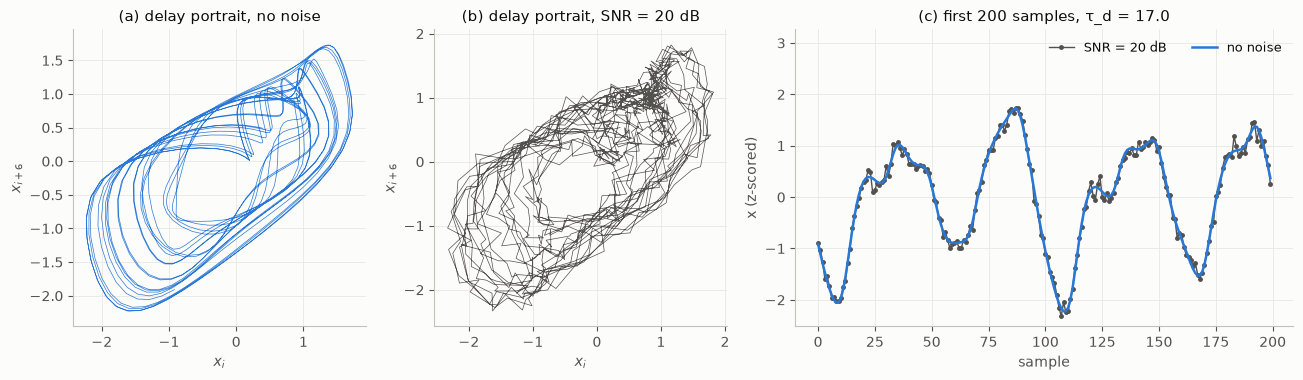

In [3]:
x  = xr.zscore(simulate(P_CHAOS, n_raw))
xn = xr.add_noise(x, snr_db=20, seed=1)
g  = np.random.default_rng(2).standard_normal(n_raw)              # stochastic reference

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.7]})
for ax, s, key, name, tag in [(axes[0], x, "clean", "no noise", "a"), (axes[1], xn, "ink", "SNR = 20 dB", "b")]:
    ax.plot(s[:-tau], s[tau:], color=C[key], lw=0.5)
    ax.set(xlabel=r"$x_i$", ylabel=rf"$x_{{i+{tau}}}$", title=f"({tag}) delay portrait, {name}")
    ax.set_aspect("equal", adjustable="datalim")
k = np.arange(200)
axes[2].plot(k, xn[k], color=C["ink"], lw=1, marker="o", ms=2.5, label="SNR = 20 dB")
axes[2].plot(k, x[k], color=C["clean"], label="no noise")
axes[2].set(xlabel="sample", ylabel="x (z-scored)", title=f"(c) first 200 samples, {PNAME} = {P_CHAOS}")
lo, hi = axes[2].get_ylim()
axes[2].set_ylim(lo, hi + 0.3 * (hi - lo))                        # headroom for the legend
axes[2].legend(loc="upper right", ncol=2)
plt.tight_layout()

## 2. Choosing τm

As in the paper (Sec. II, Fig. 3), τm must be larger than the spacing of noise-induced minima (≈ 3 samples for white noise) and smaller than the first lag where the ACF drops to ≤ 0.1. `suggest_tau_m` returns both bounds and their midpoint, which is used from here on.

In [4]:
tm = xr.suggest_tau_m(xn, m=m, tau=tau)
tau_m = tm["recommended"]
print(f"first ACF <= 0.1 at lag {xr.acf_first_crossing(xn)} samples;  suggest_tau_m -> {tm};  using tau_m = {tau_m}")

first ACF <= 0.1 at lag 12 samples;  suggest_tau_m -> {'lower': 3.0, 'upper': 12, 'recommended': 8};  using tau_m = 8


## 3. Recurrence plots under noise

Four RPs of the same chaotic signal (zoom on the first 300 samples). ε is the 5th percentile of each signal's own distances. The table adds a white-noise RP as the stochastic reference.

τ_d = 17.0           RR   DET   LAM   DDET
no noise, LM2P     0.011  0.96  0.17  +1.43
20 dB, threshold   0.050  0.90  0.95  +4.19
20 dB, LMT         0.015  0.40  0.71  +1.23
20 dB, LM2P        0.012  0.46  0.63  +1.14
white noise, LM2P  0.032  0.05  0.08  -1.10


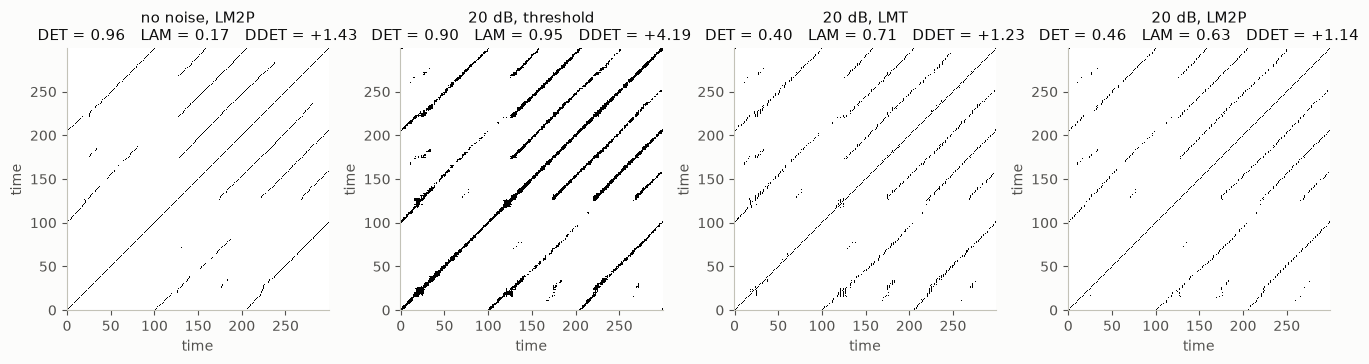

In [5]:
def rp_of(D, tm=tau_m):
    return xr.local_minima_rp(D, xr.eps_from_percentile(D, 5), tm)    # LM2P (LMT if tm is None)

Dc, Dn, Dg = (xr.distance_matrix(xr.embed(s, m, tau)) for s in (x, xn, g))
R = {"no noise, LM2P": rp_of(Dc), "20 dB, threshold": xr.threshold_rp(Dn, xr.eps_from_percentile(Dn, 5)),
     "20 dB, LMT": rp_of(Dn, None), "20 dB, LM2P": rp_of(Dn), "white noise, LM2P": rp_of(Dg)}
q = {k: (xr.rqa(r), xr.ddet(r)) for k, r in R.items()}

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.9))
for ax, k in zip(axes, list(R)[:4]):
    xr.plot_rp(R[k], ax, 0, 300, title=f"{k}\nDET = {q[k][0]['DET']:.2f}   LAM = {q[k][0]['LAM']:.2f}   DDET = {q[k][1].ddet:+.2f}")
plt.tight_layout()

print(f"{PNAME} = {P_CHAOS}       {'RR':>6s}{'DET':>6s}{'LAM':>6s}{'DDET':>7s}")
for k, (r, d) in q.items():
    print(f"{k:18s}{r['RR']:6.3f}{r['DET']:6.2f}{r['LAM']:6.2f}{d.ddet:+7.2f}")

**What to look for.**

* The threshold RP again shows thick lines and blocks (LAM 0.95) and an inflated DDET (+4.19).
* LMT and LM2P keep DDET near the noise-free value (+1.23 and +1.14, against +1.43). LM2P has the higher DET (0.46 vs 0.40) and the lower LAM (0.63 vs 0.71).

## 4. Parameter sweep: periodic windows versus chaos

$\tau_d$ = 8 … 30 in steps of 0.25, with and without 20 dB noise.

**Ground truth.** Each parameter value is simulated once on a 5× finer time grid with the same integration step. The RP signal is every 5th sample of the first part. The later part gives the bifurcation diagram, the local maxima of $x(t)$. A periodic orbit repeats a few maximum values, while a chaotic one almost never repeats. Values where fewer than 25 % of the maxima are distinct (at a resolution of 0.1 % of the standard deviation) are marked periodic and shaded in every panel. Points right at a bifurcation converge slowly and can land on either side.

**Score.** The AUC is the probability that a periodic parameter value scores higher than a chaotic one. 1 means perfect separation, 0.5 means none.

In [6]:
fine, n_bif = 5, 3000
t0 = time.time()
long = simulate(grid, n_raw + n_bif, fine)                          # all parameter values at once
sig  = xr.zscore(long[:, : n_raw * fine : fine])                   # RP signal, sampled every dt
tail = long[:, n_raw * fine :]                                      # later part, fine grid
peaks = [xr.peak_values(s) for s in tail]
distinct = np.array([np.unique(np.round(p / (1e-3 * s.std()))).size / p.size for p, s in zip(peaks, tail)])
periodic = distinct < 0.25

keys = ["clean", "LMT", "LM2P"]
det = {k: np.empty(len(grid)) for k in keys}
dd  = {k: np.empty(len(grid)) for k in keys}
for n, s in enumerate(sig):
    Dc_ = xr.distance_matrix(xr.embed(s, m, tau))
    Dn_ = xr.distance_matrix(xr.embed(xr.add_noise(s, 20, seed=n), m, tau))
    for k, r in [("clean", rp_of(Dc_)), ("LMT", rp_of(Dn_, None)), ("LM2P", rp_of(Dn_))]:
        det[k][n], dd[k][n] = xr.rqa(r)["DET"], xr.ddet(r).ddet
print(f"sweep done in {time.time() - t0:.0f} s;  periodic: {periodic.sum()} of {len(grid)} values")

def shade(ax):
    half = (grid[1] - grid[0]) / 2
    edges = np.flatnonzero(np.diff(np.r_[0, periodic.astype(int), 0]))
    for a, b in zip(edges[::2], edges[1::2]):
        ax.axvspan(grid[a] - half, grid[b - 1] + half, color="#efeee9", lw=0, zorder=0)

def auc(v):
    a, b = v[periodic][:, None], v[~periodic][None, :]
    return float(np.mean((a > b) + 0.5 * (a == b)))

sweep done in 39 s;  periodic: 36 of 89 values


                             AUC DET  AUC DDET   DDET median: chaotic  periodic
Mackey–Glass, no noise          0.95      1.00                  +0.99     +6.70
Mackey–Glass + noise, LMT       0.97      0.98                  +0.89     +5.24
Mackey–Glass + noise, LM2P      0.98      0.99                  +0.77     +4.97
Gaussian white noise                             DDET -1.10


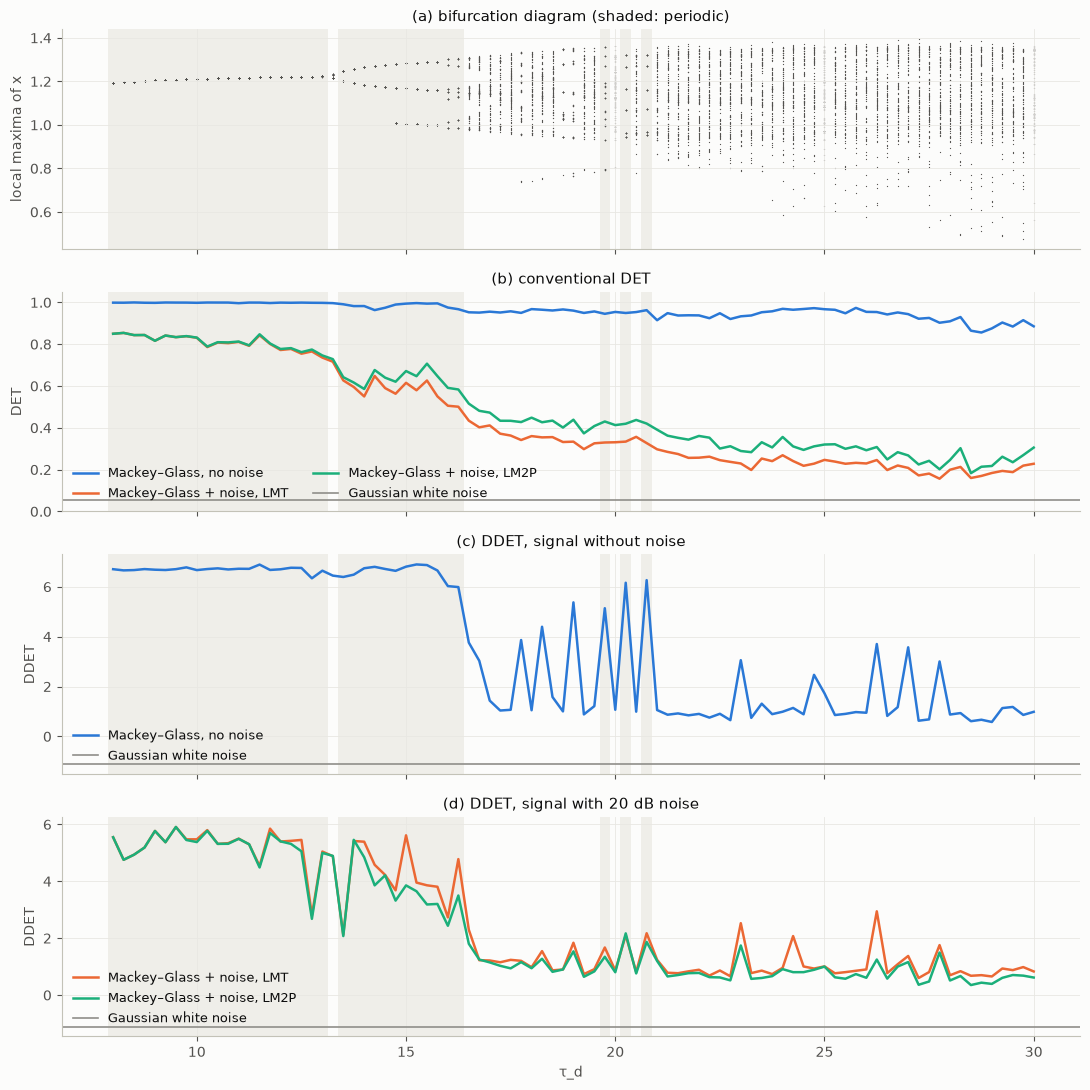

In [7]:
noise_det, noise_dd = q["white noise, LM2P"][0]["DET"], q["white noise, LM2P"][1].ddet
fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
ax = axes[0]; shade(ax)
for gv, p in zip(grid, peaks):
    p = p[-150:]
    ax.scatter(np.full(p.size, gv), p, s=0.8, color=C["ink"], lw=0, rasterized=True)
ax.set(ylabel="local maxima of x", title="(a) bifurcation diagram (shaded: periodic)")

ax = axes[1]; shade(ax)
for k in keys:
    ax.plot(grid, det[k], color=C[k], label=LABEL[k])
ax.axhline(noise_det, color=C["noise"], lw=1.2, label=LABEL["noise"])
ax.set(ylabel="DET", ylim=(0, 1.05), title="(b) conventional DET")
ax.legend(loc="lower left", ncol=2)

ax = axes[2]; shade(ax)
ax.plot(grid, dd["clean"], color=C["clean"], label=LABEL["clean"])
ax.axhline(noise_dd, color=C["noise"], lw=1.2, label=LABEL["noise"])
ax.set(ylabel="DDET", title="(c) DDET, signal without noise")
ax.legend(loc="lower left")

ax = axes[3]; shade(ax)
for k in keys[1:]:
    ax.plot(grid, dd[k], color=C[k], label=LABEL[k])
ax.axhline(noise_dd, color=C["noise"], lw=1.2, label=LABEL["noise"])
ax.set(ylabel="DDET", xlabel=PNAME, title="(d) DDET, signal with 20 dB noise")
ax.legend(loc="lower left")
plt.tight_layout()

print(f"{'':28s}{'AUC DET':>8s}{'AUC DDET':>10s}   DDET median: chaotic  periodic")
for k in keys:
    print(f"{LABEL[k]:28s}{auc(det[k]):8.2f}{auc(dd[k]):10.2f}   {np.median(dd[k][~periodic]):+20.2f}{np.median(dd[k][periodic]):+10.2f}")
print(f"{LABEL['noise']:28s}{'':18s}   DDET {noise_dd:+.2f}")

**Result.**

* In the periodic range (τ_d < 16.5) DDET is ≈ 5–6.7. In the chaotic range it is ≈ 1 without noise and ≈ 0.8 with 20 dB noise (AUC 0.99–1.00).
* With noise, DET also separates the two ranges (AUC 0.98): Mackey–Glass chaos becomes more complex as the delay grows, and DET falls steadily. DDET also marks the narrow windows near τ_d ≈ 20–21 with small bumps (≈ 2).
* The dips of the noisy curves at τ_d ≈ 13–13.5 lie at the first period doubling, where the orbit converges slowly.
* The isolated spikes of the noise-free DDET in the chaotic range (for example at τ_d = 18.25 or 23) come from a single short window near the RP corner that a line happens to fill. This is the effect described in `lorenz_example.ipynb` §9, and `xr.ddet(R, max_lag=N // 2)` removes it. With noise those corner lines break up and the spikes disappear.

## 5. How much noise is too much?

DET and DDET of the LM2P plot for one chaotic and one periodic parameter value as the noise grows. The left-most point is the signal without noise.

chaotic, τ_d = 17.0        no noise, 30, 25, 20, 15, 10, 5 dB
   DET  [0.96 0.77 0.63 0.45 0.28 0.18 0.11]
   DDET [ 1.43  1.58  1.29  1.07  0.65  0.23 -0.29]


periodic, τ_d = 14.0       no noise, 30, 25, 20, 15, 10, 5 dB
   DET  [0.98 0.9  0.8  0.63 0.39 0.24 0.14]
   DDET [ 6.74  6.62  6.19  5.07  1.73  0.63 -0.07]


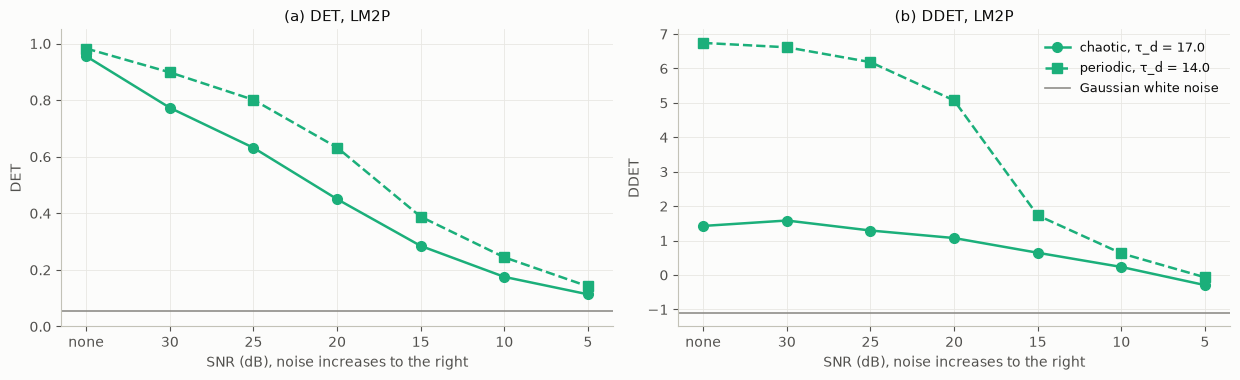

In [8]:
snrs = [30, 25, 20, 15, 10, 5]
xpos = [35] + snrs                                                   # 35 stands for "no noise"
pair = xr.zscore(simulate(np.array([P_CHAOS, P_PER]), n_raw))
lm2p = lambda s: rp_of(xr.distance_matrix(xr.embed(s, m, tau)))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharex=True)
for s, name, mk, ls in [(pair[0], f"chaotic, {PNAME} = {P_CHAOS}", "o", "-"), (pair[1], f"periodic, {PNAME} = {P_PER}", "s", "--")]:
    Rs = [lm2p(s)] + [lm2p(xr.add_noise(s, snr, seed=3)) for snr in snrs]
    vals = {"DET": [xr.rqa(r)["DET"] for r in Rs], "DDET": [xr.ddet(r).ddet for r in Rs]}
    for ax, (lab, v) in zip(axes, vals.items()):
        ax.plot(xpos, v, color=C["LM2P"], marker=mk, ls=ls, ms=7, label=name)
    print(f"{name:26s} no noise, {', '.join(map(str, snrs))} dB\n   DET  {np.round(vals['DET'], 2)}\n   DDET {np.round(vals['DDET'], 2)}")
axes[0].axhline(noise_det, color=C["noise"], lw=1.2, label=LABEL["noise"])
axes[1].axhline(noise_dd, color=C["noise"], lw=1.2, label=LABEL["noise"])
axes[0].set(ylabel="DET", ylim=(0, 1.05), title="(a) DET, LM2P")
axes[1].set(ylabel="DDET", title="(b) DDET, LM2P")
for ax in axes:
    ax.set_xticks(xpos, ["none"] + [str(v) for v in snrs])
    ax.set_xlabel("SNR (dB), noise increases to the right")
axes[0].invert_xaxis()                                               # x is shared
axes[1].legend(loc="upper right")
plt.tight_layout()

Chaotic (τ_d = 17): DDET 1.43 without noise, 1.07 at 20 dB, 0.65 at 15 dB. Periodic (τ_d = 14): 6.74, 5.07 at 20 dB, 1.73 at 15 dB. The periodic orbit stays clearly above the chaotic one down to 15 dB. Below that, both move towards the white-noise level.

## 6. Sampling rate and embedding dimension

`ws` and `d_max` are counted in samples. Noise shifts each point of a diagonal line sideways by a few samples. With finer sampling the same shift spans more samples, so more lines break apart and DDET drops. The cell below analyses one record twice under 20 dB noise: at twice the sampling rate used here, and downsampled to every 2nd sample. It does this for m = 3 and m = 5. The embedding delay τ is scaled so that it covers the same time, and τm comes from `suggest_tau_m` each time.

In [9]:
rec = xr.zscore(simulate(np.array([P_CHAOS, P_PER]), n_raw, fine=2))          # sampled every dt / 2
noisy = [xr.add_noise(s, 20, seed=4) for s in rec] + [np.random.default_rng(5).standard_normal(rec.shape[-1])]

def ddet_lm2p(s, mm, tt, tm_):
    D_ = xr.distance_matrix(xr.embed(s, mm, tt))
    return xr.ddet(xr.local_minima_rp(D_, xr.eps_from_percentile(D_, 5), tm_)).ddet

print(f"DDET of LM2P plots, 20 dB noise, same record ({rec.shape[-1] * dt / 2:.0f} time units)\n")
print(f"{'sampling':24s}{'N':>6s}{'m':>3s}{'tau':>5s}{'tau_m':>6s}{'chaotic':>9s}{'periodic':>10s}{'gap':>6s}{'white noise':>13s}")
for name, step, tt in [("dt / 2 (2x finer)", 1, 2 * tau), ("dt (every 2nd sample)", 2, tau)]:
    for mm in (3, 5):
        tm_ = xr.suggest_tau_m(noisy[0][::step], m=mm, tau=tt)["recommended"]
        c_, p_, w_ = (ddet_lm2p(s[::step], mm, tt, tm_) for s in noisy)
        n_ = noisy[0][::step].size - (mm - 1) * tt
        print(f"{name:24s}{n_:6d}{mm:3d}{tt:5d}{tm_:6d}{c_:+9.2f}{p_:+10.2f}{p_ - c_:+6.2f}{w_:+13.2f}")

DDET of LM2P plots, 20 dB noise, same record (1024 time units)

sampling                     N  m  tau tau_m  chaotic  periodic   gap  white noise


dt / 2 (2x finer)         2024  3   12    13    +0.40     +1.00 +0.60        -1.14


dt / 2 (2x finer)         2000  5   12    13    +0.49     +1.32 +0.83        -1.16


dt (every 2nd sample)     1012  3    6     8    +1.45     +2.76 +1.31        -1.01


dt (every 2nd sample)     1000  5    6     8    +1.37     +4.27 +2.90        -1.03


The base sampling (dt = 1) already gives about 50 samples per oscillation. Sampling twice as finely shrinks the gap between periodic and chaotic DDET (0.60 for m = 3, 0.83 for m = 5). Downsampling widens it (1.31 and 2.90). m = 5 helps more here than for the two ODE examples, because the Mackey–Glass attractor is higher-dimensional.

## 7. Distance from random noise

How far is Mackey–Glass from random noise? The DDET of white noise depends on the settings (`ddet_white_noise.ipynb`), so every value is compared with a baseline computed with this notebook's settings: 20 Gaussian white-noise series analysed exactly like the signal. `xr.ddet_baseline` returns the DDET and the DET of these series.

$\Delta DDET = DDET - \overline{DDET}_{noise}$ and $\Delta DET = DET - \overline{DET}_{noise}$. ΔDDET is a log ratio: ΔDDET = 2 means 7.4 times more connected diagonal structure than noise. ΔDET is a plain difference of fractions, at most 1 − baseline. Because the units differ, the table also gives scale-free numbers: the closest chaotic value in white-noise standard deviations, and the AUC for telling periodic from chaotic values (section 4).

white-noise baseline, 20 series: DDET -1.01 ± 0.08 (model -1.01),  DET 0.057 ± 0.004

                             median Δ, chaotic  median Δ, periodic    closest chaotic (noise sd)  AUC periodic vs chaotic
                                 DDET      DET      DDET       DET           DDET            DET        DDET          DET
Mackey–Glass, no noise          +2.00    +0.89     +7.71     +0.94    +1.59 ( 21)    +0.80 (183)        1.00         0.95
Mackey–Glass + noise, LM2P      +1.78    +0.26     +5.98     +0.72    +1.36 ( 18)    +0.13 ( 29)        0.99         0.98


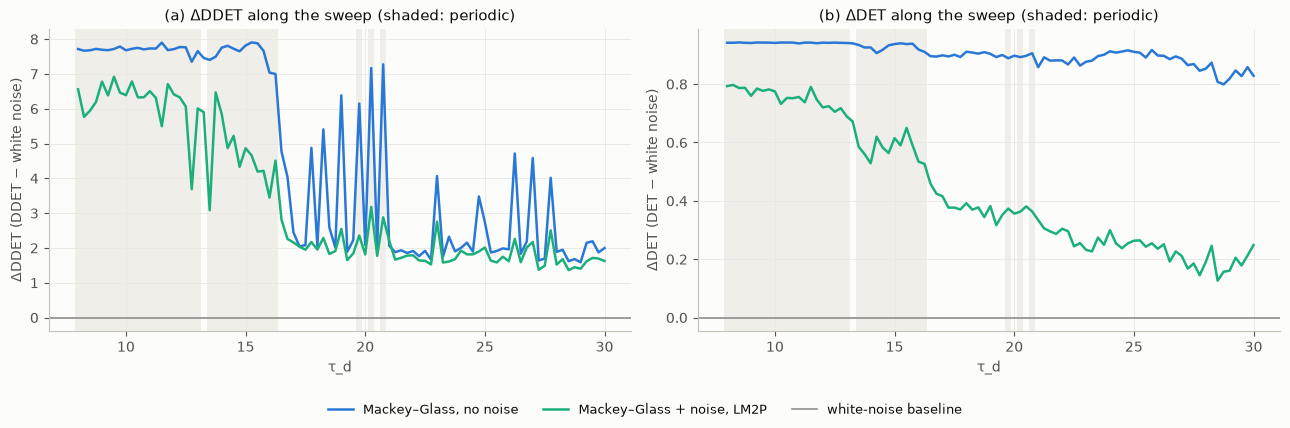

In [10]:
base = xr.ddet_baseline(n=n_raw, m=m, tau=tau, tau_m=tau_m, n_real=20, seed=0)    # white noise, this notebook's settings
delta = {"DDET": {k: dd[k] - base["mean"] for k in ("clean", "LM2P")},
         "DET":  {k: det[k] - base["det_mean"] for k in ("clean", "LM2P")}}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharex=True)
for ax, (lab, v), tag in zip(axes, delta.items(), "ab"):
    shade(ax)
    ax.axhline(0, color=C["noise"], lw=1.2)
    for k in ("clean", "LM2P"):
        ax.plot(grid, v[k], color=C[k])
    ax.set(xlabel=PNAME, ylabel=f"Δ{lab} ({lab} − white noise)", title=f"({tag}) Δ{lab} along the sweep (shaded: periodic)")
handles = [Line2D([], [], color=C[k], label=LABEL[k]) for k in ("clean", "LM2P")] + [Line2D([], [], color=C["noise"], lw=1.2, label="white-noise baseline")]
fig.legend(handles=handles, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.08, 1, 1))

print(f"white-noise baseline, 20 series: DDET {base['mean']:+.2f} ± {base['sd']:.2f} (model {base['theory']:+.2f}),  DET {base['det_mean']:.3f} ± {base['det_sd']:.3f}\n")
print(f"{'':28s}{'median Δ, chaotic':>18s}{'median Δ, periodic':>20s}{'closest chaotic (noise sd)':>30s}{'AUC periodic vs chaotic':>25s}")
print(f"{'':28s}{'DDET':>9s}{'DET':>9s}{'DDET':>10s}{'DET':>10s}{'DDET':>15s}{'DET':>15s}{'DDET':>12s}{'DET':>13s}")
for k in ("clean", "LM2P"):
    dD, dT = delta["DDET"][k], delta["DET"][k]
    cD, cT = dD[~periodic].min(), dT[~periodic].min()
    print(f"{LABEL[k]:28s}{np.median(dD[~periodic]):+9.2f}{np.median(dT[~periodic]):+9.2f}{np.median(dD[periodic]):+10.2f}{np.median(dT[periodic]):+10.2f}"
          f"{cD:+9.2f} ({cD / base['sd']:3.0f}){cT:+9.2f} ({cT / base['det_sd']:3.0f}){auc(dd[k]):12.2f}{auc(det[k]):13.2f}")

**Signal or noise, as the noise grows?** The chaotic reference signal of section 5 is cut into 20 segments of the same length, and each segment gets its own noise. The 20 values are compared with 20 noise series:

* **white noise**: the 20 baseline series above;
* **red noise**: AR(1) noise with the same lag-1 autocorrelation φ as the noisy signal (`xr.ar1_noise`). This is the usual "red noise" null hypothesis: noise with memory, as most real measurement noise has.

AUC is the probability that a signal segment scores higher than a noise series. 1 means the signal is always recognised, 0.5 is chance, and below 0.5 the noise looks *more* deterministic than the signal. Markers are shifted slightly sideways so that overlapping values stay visible. The procedure is the same as in `ddet_white_noise.ipynb` (B5).

AUC, chaotic signal (τ_d = 17.0) vs noise: 20 segments against 20 noise series
                         20 dB   15 dB   10 dB    5 dB    0 dB   -5 dB
DDET vs white noise       1.00    1.00    1.00    1.00    1.00    0.59
DET  vs white noise       1.00    1.00    1.00    1.00    0.99    0.56
DDET vs red noise         1.00    1.00    1.00    1.00    0.92    0.51
DET  vs red noise         1.00    1.00    1.00    0.98    0.54    0.37
φ of the noisy signal    0.980   0.960   0.902   0.756   0.502   0.247
done in 88 s


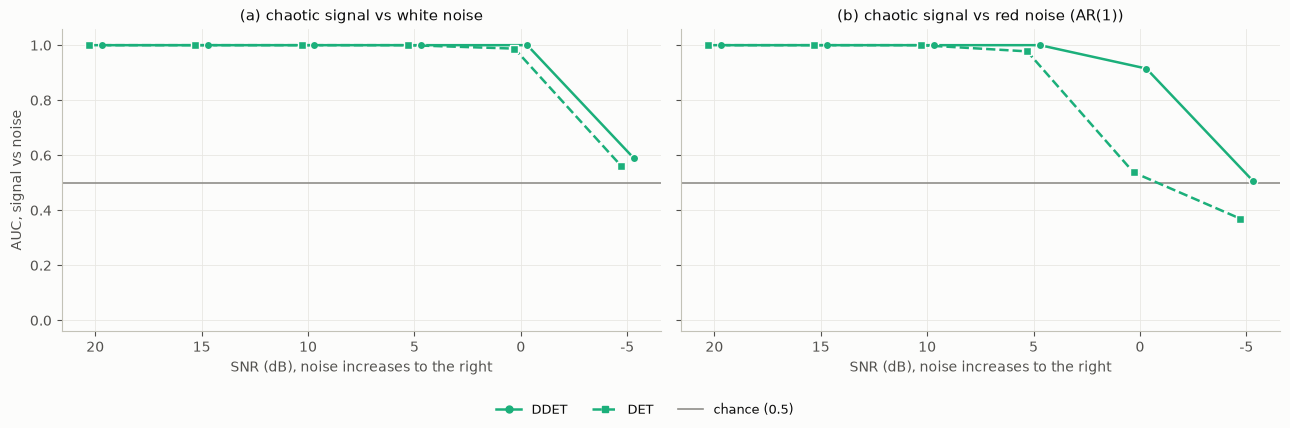

In [11]:
snrs_auc, K = [20, 15, 10, 5, 0, -5], 20

def auc_ab(a, b):                                  # P(a > b) over all pairs, ties count half
    a, b = np.asarray(a)[:, None], np.asarray(b)[None, :]
    return float(np.mean((a > b) + 0.5 * (a == b)))

def ddet_det(s):
    r = lm2p(s)
    return xr.ddet(r).ddet, xr.rqa(r)["DET"]

t0 = time.time()
long_ = simulate(P_CHAOS, n_raw * K)
segs = [xr.zscore(long_[i * n_raw:(i + 1) * n_raw]) for i in range(K)]
white = np.c_[base["values"], base["det_values"]]                  # (20, 2): DDET, DET
auc_sn = {(null, j): [] for null in ("white", "red") for j in (0, 1)}
phis = []
for snr in snrs_auc:
    noisy_ = [xr.add_noise(s, snr, seed=100 * i + 7) for i, s in enumerate(segs)]
    sig_ = np.array([ddet_det(s) for s in noisy_])
    phi = float(np.mean([np.corrcoef(s[:-1], s[1:])[0, 1] for s in noisy_]))
    rng = np.random.default_rng(1)
    red = np.array([ddet_det(xr.ar1_noise(n_raw, phi, rng)) for _ in range(K)])
    phis.append(phi)
    for j in (0, 1):
        auc_sn[("white", j)].append(auc_ab(sig_[:, j], white[:, j]))
        auc_sn[("red", j)].append(auc_ab(sig_[:, j], red[:, j]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharex=True, sharey=True)
for ax, null, title in zip(axes, ("white", "red"), ("(a) chaotic signal vs white noise", "(b) chaotic signal vs red noise (AR(1))")):
    ax.axhline(0.5, color=C["noise"], lw=1.2)
    for j, ls, mk, dx in [(0, "-", "o", -0.3), (1, "--", "s", 0.3)]:
        ax.plot(np.array(snrs_auc) + dx, auc_sn[(null, j)], color=C["LM2P"], ls=ls, marker=mk, ms=6, mec="#fcfcfb", mew=1)
    ax.set_xticks(snrs_auc, [str(v) for v in snrs_auc])
    ax.set(xlabel="SNR (dB), noise increases to the right", title=title)
axes[0].invert_xaxis()                                              # x is shared
axes[0].set(ylabel="AUC, signal vs noise", ylim=(-0.04, 1.06))
handles = [Line2D([], [], color=C["LM2P"], ls="-", marker="o", label="DDET"), Line2D([], [], color=C["LM2P"], ls="--", marker="s", label="DET"),
           Line2D([], [], color=C["noise"], lw=1.2, label="chance (0.5)")]
fig.legend(handles=handles, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.08, 1, 1))

print(f"AUC, chaotic signal ({PNAME} = {P_CHAOS}) vs noise: {K} segments against {K} noise series")
print(f"{'':22s}" + "".join(f"{str(v) + ' dB':>8s}" for v in snrs_auc))
for (null, j), v in auc_sn.items():
    print(f"{['DDET', 'DET'][j]:5s}vs {null + ' noise':14s}" + "".join(f"{a:8.2f}" for a in v))
print(f"{'φ of the noisy signal':22s}" + "".join(f"{p_:8.3f}" for p_ in phis))
print(f"done in {time.time() - t0:.0f} s")

**Result.**

* **Distance.** With this notebook's settings, white noise gives DDET −1.01 ± 0.08 and DET 0.057 ± 0.004. With 20 dB noise, chaotic Mackey–Glass sits at ΔDDET +1.78 (median; +2.00 without noise). The closest chaotic value is +1.36, 18 noise standard deviations away. The periodic values reach +5.98.
* **DET.** With noise, chaotic ΔDET falls to +0.26 (closest +0.13) while the periodic orbits keep +0.72. Here DET separates the regimes almost as well as DDET (AUC 0.98 against 0.99), because chaos grows more complex with τ_d (section 4).
* **Signal or noise.** Against white noise, both measures recognise the chaotic signal down to 0 dB (AUC ≥ 0.99). Against red noise, DDET holds down to 0 dB (0.92). DET is still 0.98 at 5 dB but drops to chance at 0 dB (0.54).

## 8. Takeaways for the Mackey–Glass system

* DDET separates the periodic range from chaos with and without noise. Inside the chaotic range it also falls slowly with τ_d, as the attractor becomes more complex.
* For this system DET of the noisy signal works too, because chaos at large delays is complex enough for DET to drop clearly. DDET remains the more sensitive indicator for narrow windows.
* The classic benchmark τ_d = 17 is weakly chaotic. Its DDET (≈ 1.1–1.4) lies between the periodic orbits and the more complex chaos at larger delays.
* Use m ≥ 5 for this delay system, and do not oversample.
* Chaotic Mackey–Glass stays ≈ +1.8 above white noise at 20 dB (section 7). Against red noise, DDET recognises it down to 0 dB, DET only down to 5 dB.